# Q1. Which species, if any, are continuing to decline?

A continuing decline means down from 1977–1990 to 1991–2005 **and** down again to 2006–2020, with the recent and overall drops both clear.

In [1]:
from pathlib import Path
import textwrap, warnings, logging
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import kruskal
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
TRAITS_PATH = Path("species_traits_provisional.csv")   # diet, habitat, nest, movement, size (provisional, editable)
OUTPUT_DIR = Path("outputs")
PDF_NAME = "Q1_Continuing_Declines.pdf"

# Three Atlas windows: a species "continues to decline" if it fell from the 1st to the 2nd AND from the 2nd to the 3rd
WINDOWS = {"A": (1977, 1990), "B": (1991, 2005), "C": (2006, 2020)}
LIST_BAND = (15, 45)            # only survey lists with this many species, so list length is the same in every window
SHEETS_PER_SQUARE = 4           # survey sheets drawn per grid square in EACH window
REPEATS = 25                    # random draws averaged together
BOOTSTRAP = 400                 # resamples of grid squares for the uncertainty ranges
MIN_OCCUPANCY = 8               # % of squares a species must reach in one window to be assessed

# Q2A - map
CELL_DEG = 1.0                  # map cell size in degrees (about 100 km)
MIN_CELL_SQUARES = 4            # grid squares a map cell needs

ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
INTRODUCED = [957, 989, 991, 995, 996, 998, 999]
SPLIT_NAMES = [291, 294]        # Mallee/Australian Ringneck: a naming change, not a real change
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
WLAB = {k: f"{a}–{b}" for k, (a, b) in WINDOWS.items()}
print("Data file:", DATA_PATH.resolve())

Data file: /home/user/birdbreed/combined_atlas_des.parquet


In [2]:
# ---- Chart style (same colour-blind-safe palette as the first client report) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DARK_BLUE, LIGHT_BLUE, LIGHT_RED = "#184f95", "#86b6ef", "#f4a7a6"

mpl.rcParams.update({
    "font.family": ["Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page
HALO = [mpl.patheffects.withStroke(linewidth=2.4, foreground="white")]

def headline(fig, title, subtitle):
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

def answer(Q):
    display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q["findings"]) +
                     f"\n\n**What it means:** {Q['meaning']}\n\n*Caution: {Q['caveat']}*"))

TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04),
         "Port Macquarie": (-31.43, 152.91), "Lismore": (-28.81, 153.28), "Albury": (-36.08, 146.92),
         "Bathurst": (-33.42, 149.58), "Tamworth": (-31.09, 150.93), "Moree": (-29.47, 149.84),
         "Wollongong": (-34.42, 150.89), "Nowra": (-34.88, 150.60), "Bega": (-36.67, 149.84),
         "Cooma": (-36.24, 149.12), "Goulburn": (-34.75, 149.72), "Orange": (-33.28, 149.10),
         "Mudgee": (-32.60, 149.59), "Coonabarabran": (-31.27, 149.28), "Narrabri": (-30.33, 149.78),
         "Grafton": (-29.69, 152.93), "Coffs Harbour": (-30.30, 153.11), "Taree": (-31.90, 152.46),
         "Forbes": (-33.38, 148.01), "Parkes": (-33.14, 148.17), "Cobar": (-31.50, 145.84),
         "Hay": (-34.51, 144.84), "Deniliquin": (-35.53, 144.96), "Narrandera": (-34.75, 146.55),
         "Young": (-34.31, 148.30), "Queanbeyan": (-35.35, 149.23), "Katoomba": (-33.71, 150.31),
         "Gosford": (-33.43, 151.34), "Maitland": (-32.73, 151.56), "Singleton": (-32.57, 151.17),
         "Muswellbrook": (-32.26, 150.89), "Glen Innes": (-29.74, 151.74), "Tenterfield": (-29.05, 152.02),
         "Inverell": (-29.77, 151.11), "Gunnedah": (-30.98, 150.25), "Walgett": (-30.02, 148.12),
         "Wilcannia": (-31.56, 143.38), "Ivanhoe": (-32.90, 144.30), "Balranald": (-34.64, 143.56),
         "Wentworth": (-34.11, 141.92), "Tibooburra": (-29.43, 142.01), "Nyngan": (-31.56, 147.19),
         "Lithgow": (-33.48, 150.16), "Batemans Bay": (-35.71, 150.18), "Eden": (-37.07, 149.90),
         "Tumut": (-35.30, 148.22), "Kempsey": (-31.08, 152.83), "Ballina": (-28.87, 153.56),
         "Leeton": (-34.55, 146.40), "Condobolin": (-33.09, 147.15), "West Wyalong": (-33.92, 147.21),
         "Warren": (-31.70, 147.83), "Coonamble": (-30.95, 148.39), "Brewarrina": (-29.96, 146.86),
         "Menindee": (-32.39, 142.42), "Jindabyne": (-36.42, 148.62), "Scone": (-32.05, 150.87)}

def nearest_town(lat, lon):
    k = min(TOWNS, key=lambda t: (TOWNS[t][0] - lat) ** 2 + ((TOWNS[t][1] - lon) * np.cos(np.radians(lat))) ** 2)
    dist = 111 * np.hypot(TOWNS[k][0] - lat, (TOWNS[k][1] - lon) * np.cos(np.radians(lat)))
    return k if dist < 15 else f"near {k}"

def nsw_axes(ax):
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

def label_towns(ax, towns, size=7.2):
    for t in towns:
        la, lo = TOWNS[t]
        ax.plot(lo, la, "o", ms=2.8, color=INK, zorder=5)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=size, color=INK, zorder=5, path_effects=HALO)


DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}

## Data
Atlas surveys, 1977–2020, in three periods. To compare fairly, each period uses the same grid squares, the same
number of single-month survey lists per square (4), and lists of similar length (15–45 species). Each species is
measured as the share of squares where it was recorded, relative to the typical species.

In [3]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "single_month",
        "klat", "klon", "region", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)    # grid codes are square centres
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
data = data[data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)]
data["square"] = data["klat"].astype(int) * 100000 + data["klon"].astype(int)
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

atlas = data[(data["source"] == "Atlas") & ~data["is_collection"]
             & data["year"].between(WINDOWS["A"][0], WINDOWS["C"][1])].copy()
atlas["list_len"] = atlas["sheet_id"].map(atlas.groupby("sheet_id", observed=True).size()).astype(int)
atlas = atlas[atlas["list_len"].between(*LIST_BAND) & atlas["single_month"].astype(bool)]
edges = [WINDOWS["A"][0] - 1] + [WINDOWS[k][1] for k in "ABC"]
atlas["window"] = pd.cut(atlas["year"], edges, labels=list("ABC")).astype(str)

sheets = atlas.drop_duplicates("sheet_id")[["sheet_id", "square", "window", "list_len", "region"]]
per_sq = sheets.groupby(["square", "window"]).size().unstack(fill_value=0)
SQUARES = per_sq[(per_sq[list("ABC")] >= SHEETS_PER_SQUARE).all(axis=1)].index
sheets = sheets[sheets["square"].isin(SQUARES)]
rows = atlas[atlas["sheet_id"].isin(sheets["sheet_id"])][["sheet_id", "species_id", "square", "window", "breeding"]]

det, mean_len = None, []
for rep in range(REPEATS):
    pick = sheets.sample(frac=1, random_state=rep)
    pick = pick[pick.groupby(["square", "window"]).cumcount() < SHEETS_PER_SQUARE]
    mean_len.append(pick.groupby("window")["list_len"].mean())
    x = rows[rows["sheet_id"].isin(pick["sheet_id"])]
    p = x.groupby(["species_id", "square", "window"]).size().gt(0).astype(float)
    det = p if det is None else det.add(p, fill_value=0)
# Probability that each species is recorded in each square and window (averaged over the draws)
det = (det / REPEATS).unstack("window", fill_value=0).reindex(columns=list("ABC"), fill_value=0)

sq_info = atlas.drop_duplicates("square").set_index("square").loc[SQUARES, ["lat", "lon", "region"]]
sq_info["zone"] = sq_info["region"].astype(str).map(ZONES)
display(pd.DataFrame({"years": pd.Series(WLAB), "average species per list": pd.concat(mean_len, axis=1).mean(axis=1).round(1),
                      "sheets available": sheets.groupby("window").size()}))
print(f"{len(SQUARES)} grid squares surveyed in all three windows "
      f"({sq_info['zone'].value_counts().reindex(ZONE_ORDER).to_dict()})")

,years,average species per list,sheets available
A,1977–1990,28.4,10709
B,1991–2005,26.8,30188
C,2006–2020,28.6,9524


432 grid squares surveyed in all three windows ({'Coast': 117, 'Tablelands': 135, 'Inland': 179})


In [4]:

logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)
PAGE_M = 0.7                                  # page margin, inches
ACCENT = BLUE

def _text(fig, y, s, size, weight="normal", color=INK, width=100, x=None, style="normal"):
    for line in textwrap.wrap(s, width=width):
        fig.text((x or PAGE_M) / A4[0], 1 - y / A4[1], line, fontsize=size, fontweight=weight, color=color, va="top",
                 fontstyle=style)
        y += size * 1.42 / 72
    return y

def _label(fig, y, s):
    fig.text(PAGE_M / A4[0], 1 - y / A4[1], s.upper(), fontsize=8.5, fontweight="bold", color=ACCENT, va="top")
    return y + 0.24

def _bullets(fig, y, items, marker_color=ACCENT, size=10, width=96, color=INK):
    for b in items:
        fig.text((PAGE_M + 0.02) / A4[0], 1 - (y - 0.01) / A4[1], "•", fontsize=size + 1, color=marker_color, va="top")
        y = _text(fig, y, b, size, width=width, x=PAGE_M + 0.22, color=color) + 0.07
    return y

def plain_page(pdf, label, title, chart, findings, causes, note, subtitle=None, chart_h=5.0):
    # White page with light typographic structure: label, title, chart, findings, speculation, note
    fig = plt.figure(figsize=A4)
    y = _label(fig, PAGE_M, label)
    y = _text(fig, y, title, 16, "bold", width=62)
    if subtitle:
        y = _text(fig, y + 0.04, subtitle, 11.5, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [1 - (y + 0.1) / A4[1]] * 2, color=GRID, lw=1))
    top = y + 0.2
    sub = fig.subfigures(3, 1, height_ratios=[top, chart_h, A4[1] - top - chart_h], hspace=0)[1]
    chart(sub)
    y = top + chart_h + 0.25
    y = _label(fig, y, "Key findings")
    y = _bullets(fig, y, findings) + 0.12
    y = _label(fig, y, "Possible causes  ·  our speculation, not tested here")
    y = _bullets(fig, y, causes, marker_color=MUTED, size=9.4, width=104, color=INK2)
    fig.add_artist(mpl.lines.Line2D([PAGE_M / A4[0], 1 - PAGE_M / A4[0]], [(PAGE_M + 0.42) / A4[1]] * 2, color=GRID, lw=0.8))
    _text(fig, A4[1] - PAGE_M - 0.32, note, 7.8, color=MUTED, width=140)
    pdf.savefig(fig); plt.close(fig)

def show_points(findings, causes):
    display(Markdown("**Key findings**\n" + "\n".join(f"* {p}" for p in findings) +
                     "\n\n**Possible causes (our speculation, not tested here)**\n" + "\n".join(f"* {c}" for c in causes)))


## Result

In [5]:
occ = det.groupby("species_id").sum() / len(SQUARES) * 100
occ = occ[occ.max(axis=1) >= MIN_OCCUPANCY].drop(SPLIT_NAMES, errors="ignore")
STEPS = {"AB": ("A", "B"), "BC": ("B", "C"), "AC": ("A", "C")}
TYPICAL = {k: (occ[b] / occ[a]).median() for k, (a, b) in STEPS.items()}
q1 = occ.copy()
q1["name"] = names.reindex(q1.index)
for k, (a, b) in STEPS.items():
    q1[k] = q1[b] / q1[a] / TYPICAL[k]          # 1 = changed like the typical species

# Uncertainty: resample grid squares
M = {w: det[w].unstack("square", fill_value=0).reindex(index=q1.index, columns=SQUARES, fill_value=0).values
     for w in "ABC"}
rng = np.random.default_rng(0)
boot = {k: [] for k in STEPS}
for _ in range(BOOTSTRAP):
    idx = rng.integers(0, len(SQUARES), len(SQUARES))
    o = {w: M[w][:, idx].mean(axis=1) for w in "ABC"}
    for k, (a, b) in STEPS.items():
        r = o[b] / o[a]
        boot[k].append(r / np.nanmedian(r))
for k in STEPS:
    arr = np.array(boot[k])
    q1[k + "_lo"], q1[k + "_hi"] = np.nanpercentile(arr, 2.5, axis=0), np.nanpercentile(arr, 97.5, axis=0)

down_recent = q1["BC_hi"] < 1
continuing = down_recent & (q1["AB"] < 1) & (q1["AC_hi"] < 1)
q1["trend"] = np.select(
    [continuing, down_recent, q1["AB_hi"] < 1, q1["AC_lo"] > 1],
    ["Continuing decline", "New decline", "Declined earlier, now steady", "Increasing"], "No clear change")
q1["introduced"] = q1.index.isin(INTRODUCED)

# Breeding check: of the sightings of each species, the share with breeding evidence (as in the first report),
# 1977-1990 vs 2006-2020, relative to the typical species (breeding was recorded less often overall)
MIN_BREEDING = 20
bs = atlas.groupby(["species_id", "window"])["breeding"].agg(["size", "sum"]).unstack(fill_value=0)
share = bs["sum"] / bs["size"]
breed_rel = share["C"] / share["A"]
breed_typ = breed_rel[bs["sum"]["A"] >= MIN_BREEDING].median()
q1["breed_records_A"] = bs["sum"]["A"].reindex(q1.index).fillna(0)
q1["breed_AC"] = (breed_rel / breed_typ).reindex(q1.index)
traits = pd.read_csv(TRAITS_PATH).set_index("species_id")
q1.sort_values("AC").round(3).to_csv(OUTPUT_DIR / "Q1_species_trends.csv")

native = q1[~q1["introduced"]]
cont = native[native["trend"] == "Continuing decline"].sort_values("AC")
cont_intro = q1[(q1["trend"] == "Continuing decline") & q1["introduced"]]
counts = native["trend"].value_counts()
cont_breed = cont[cont["breed_records_A"] >= MIN_BREEDING]
cont_ins = cont.index.isin(traits.index[traits["diet"] == "Insects"]).sum()
n_breed_down = (cont_breed["breed_AC"] < 1).sum()
display(counts.to_frame("native species"))
print("Typical species change:", {k: f"{v - 1:+.0%}" for k, v in TYPICAL.items()})
display(cont[["name", "A", "B", "C", "AB", "BC", "AC", "breed_AC"]].round(2))

,native species
trend,
Increasing,60
No clear change,42
"Declined earlier, now steady",33
Continuing decline,27
New decline,23


Typical species change: {'AB': '-4%', 'BC': '+0%', 'AC': '-4%'}


window,name,A,B,C,AB,BC,AC,breed_AC
species_id,,,,,,,,
385,Hooded Robin,14.06,7.13,3.29,0.53,0.46,0.24,0.44
337,Pallid Cuckoo,16.36,12.27,6.82,0.78,0.55,0.44,1.24
225,Little Eagle,18.11,11.56,8.14,0.66,0.70,0.47,2.69
484,Buff-rumped Thornbill,24.32,17.90,11.40,0.76,0.63,0.49,2.08
380,Scarlet Robin,16.68,10.93,7.81,0.68,0.71,0.49,1.30
260,Little Lorikeet,12.75,9.62,6.01,0.78,0.62,0.49,0.68
547,Dusky Woodswallow,40.32,25.79,20.65,0.66,0.80,0.54,0.86
369,Restless Flycatcher,41.06,30.57,21.45,0.77,0.70,0.55,0.89
416,Crested Shrike-tit,22.55,16.28,12.16,0.75,0.74,0.56,0.89


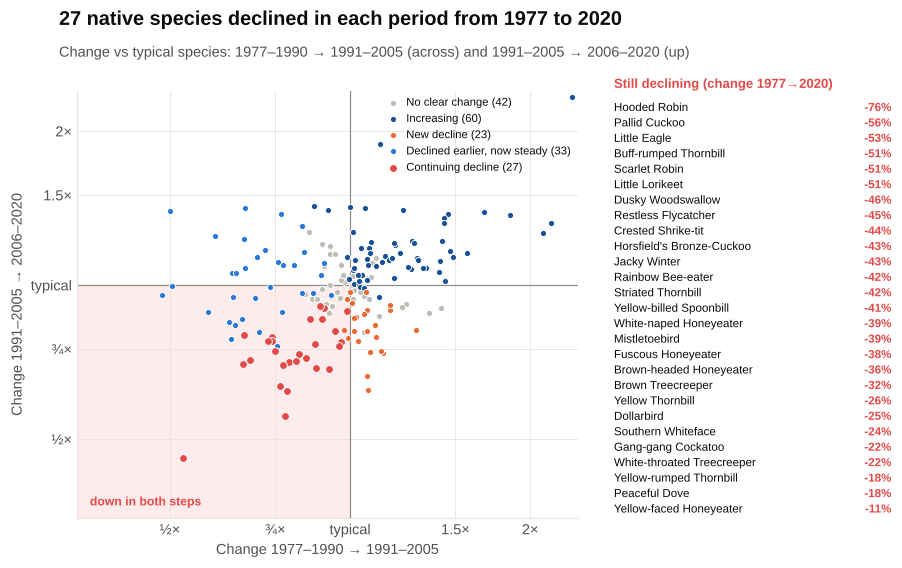

In [6]:
TREND_STYLE = {"Continuing decline": (RED, 3), "New decline": (ORANGE, 2), "Declined earlier, now steady": (BLUE, 2),
               "Increasing": (DARK_BLUE, 1), "No clear change": (GREY_PT, 0)}

def chart_q1(fig):
    headline(fig, f"{len(cont)} native species declined in each period from 1977 to 2020",
             f"Change vs typical species: {WLAB['A']} → {WLAB['B']} (across) and {WLAB['B']} → {WLAB['C']} (up)")
    ax = fig.add_gridspec(1, 1, left=0.09, right=0.64, top=0.84, bottom=0.12).subplots()
    lo, hi = 0.35, 2.4
    ax.add_patch(Rectangle((lo, lo), 1 - lo, 1 - lo, color="#fdeceb", lw=0, zorder=0))
    ax.axvline(1, color=MUTED, lw=0.8, zorder=1); ax.axhline(1, color=MUTED, lw=0.8, zorder=1)
    for t, (col, z) in sorted(TREND_STYLE.items(), key=lambda kv: kv[1][1]):
        v = native[native["trend"] == t]
        ax.scatter(v["AB"].clip(lo * 1.02, hi / 1.02), v["BC"].clip(lo * 1.02, hi / 1.02), s=26 if z == 3 else 16,
                   color=col, edgecolor="white", lw=0.6, zorder=2 + z, label=f"{t} ({len(v)})")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.minorticks_off()
    ticks = [0.5, 0.75, 1, 1.5, 2]
    labs = ["½×", "¾×", "typical", "1.5×", "2×"]
    ax.set_xticks(ticks, labs); ax.set_yticks(ticks, labs)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(f"Change {WLAB['A']} → {WLAB['B']}"); ax.set_ylabel(f"Change {WLAB['B']} → {WLAB['C']}")
    ax.text(lo * 1.05, lo * 1.06, "down in both steps", fontsize=8, color=RED, fontweight="bold")
    ax.legend(loc="upper right", fontsize=7.4, handletextpad=0.2, borderaxespad=0.2)
    # Named list of the continuing decliners
    fig.text(0.68, 0.84, f"Still declining (change {WLAB['A'][:4]}→{WLAB['C'][-4:]})", fontsize=8.6,
             fontweight="bold", color=RED, va="bottom")
    n = len(cont)
    step = min(0.026, 0.72 / max(n, 1))
    size = 7.6 if n <= 28 else 6.9
    for i, (_, r) in enumerate(cont.iterrows()):
        y = 0.82 - i * step
        fig.text(0.68, y, r["name"], fontsize=size, va="top", color=INK)
        fig.text(0.985, y, f"{(r['AC'] - 1) * 100:+.0f}%", fontsize=size, va="top", ha="right", color=RED,
                 fontweight="bold")

show(chart_q1, "Q1_continuing_declines")

In [7]:

earlier = native[native["trend"] == "Declined earlier, now steady"]
new = native[native["trend"] == "New decline"]
Q1_POINTS = [
    f"{len(cont)} of {len(native)} native species declined in both periods. Steepest: "
    f"{', '.join(cont['name'].head(3))}.",
    f"{cont_ins} of the {len(cont)} mainly eat insects.",
    f"{len(new)} more show a new decline in {WLAB['C']}; {len(earlier)} declined earlier and are now steady.",
]
Q1_NOTE = (f"Atlas surveys {WLAB['A'][:4]}–{WLAB['C'][-4:]}; same effort per grid square in each period "
           f"({len(SQUARES)} squares). Change is relative to the typical species. "
           + (f"Introduced {' and '.join(cont_intro['name'])} also declined and are not listed. " if len(cont_intro) else "")
           + "Full table: outputs/Q1_species_trends.csv")
Q1_CAUSES = [
    "Clearing and thinning of woodland, especially in the wheat-sheep belt and tablelands, has left remnants too "
    "small and too bare for ground-feeding robins, treecreepers and thornbills. Fallen timber and leaf litter "
    "removed by grazing and firewood collection take their insects with them.",
    "Fewer insects overall, from pesticides, heavy grazing of the ground layer and the Millennium Drought "
    "(about 2001–2009), which fell within the last period and would cut food for breeding.",
    "Noisy Miners spreading through fragmented woodland (see 'Hidden Pressures') push small birds out; cuckoos "
    "probably follow the decline of the small birds they rely on as hosts.",
    "Prediction: without habitat restoration these declines continue after 2020, and the 2019–20 bushfires likely "
    "deepen them for forest species such as Gang-gang Cockatoo. Several species on the list are already "
    "listed as threatened in NSW, which fits this result.",
]
show_points(Q1_POINTS, Q1_CAUSES)


**Key findings**
* 27 of 185 native species declined in both periods. Steepest: Hooded Robin, Pallid Cuckoo, Little Eagle.
* 18 of the 27 mainly eat insects.
* 23 more show a new decline in 2006–2020; 33 declined earlier and are now steady.

**Possible causes (our speculation, not tested here)**
* Clearing and thinning of woodland, especially in the wheat-sheep belt and tablelands, has left remnants too small and too bare for ground-feeding robins, treecreepers and thornbills. Fallen timber and leaf litter removed by grazing and firewood collection take their insects with them.
* Fewer insects overall, from pesticides, heavy grazing of the ground layer and the Millennium Drought (about 2001–2009), which fell within the last period and would cut food for breeding.
* Noisy Miners spreading through fragmented woodland (see 'Hidden Pressures') push small birds out; cuckoos probably follow the decline of the small birds they rely on as hosts.
* Prediction: without habitat restoration these declines continue after 2020, and the 2019–20 bushfires likely deepen them for forest species such as Gang-gang Cockatoo. Several species on the list are already listed as threatened in NSW, which fits this result.

## PDF

In [8]:

with PdfPages(OUTPUT_DIR / PDF_NAME) as pdf:
    plain_page(pdf, "Question 1", "Which species, if any, are continuing to decline?", chart_q1, Q1_POINTS,
               Q1_CAUSES, Q1_NOTE)
    pdf.infodict()["Title"] = "Which species are continuing to decline?"
print("PDF written to", (OUTPUT_DIR / PDF_NAME).resolve())


PDF written to /home/user/birdbreed/decline_patterns/outputs/Q1_Continuing_Declines.pdf
